# SDEs on the simplest example: the Wiener process

ESE 670 Bayesian Deep Learning — student notebook.

Everything about diffusions — paths, expectations, densities, the probability-flow ODE, and running time backwards —
can be seen on Brownian motion, where every formula is explicit. We use
$$\mathrm dX_t=\sigma\,\mathrm dW_t,\qquad \sigma=\sqrt2\ \text{(so that }D=\sigma^2/2=1\text{)},$$
i.e. no drift, only noise. Three levels:

| level | object | for $\mathrm dX=\sigma\,\mathrm dW$ |
|---|---|---|
| particles | random paths | $X_t=X_0+\sigma W_t$ |
| expectations | $\frac{\mathrm d}{\mathrm dt}\mathbb E f(X_t)=\mathbb E\,\mathcal Lf(X_t)$ | $\mathcal Lf=\frac{\sigma^2}2f''$ |
| densities | Fokker–Planck equation | heat equation $\partial_t\rho=\frac{\sigma^2}2\,\partial_x^2\rho$ |

Only two numerical tools are used: **sampling** Gaussian increments, and **Euler's method** for ODEs,
$y_{k+1}=y_k+h\,f(t_k,y_k)$ (and its noisy version, Euler–Maruyama, for SDEs).

Questions are placed in the text, each followed by its solution. Try first, then run the solution cell.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
rng = np.random.default_rng(0)
sigma = np.sqrt(2.0)          # noise level; D = sigma^2 / 2 = 1

def euler(f, y0, t):
    """Euler's method for dy/dt = f(t, y) on the time grid t (t may decrease: then it runs backwards)."""
    y = [np.array(y0, float)]
    for k in range(len(t) - 1):
        y.append(y[-1] + (t[k + 1] - t[k]) * f(t[k], y[-1]))
    return np.array(y)

def euler_maruyama(drift, y0, t, sigma=sigma):
    """Euler-Maruyama for dY = drift(t, Y) dt + sigma dW on the increasing time grid t."""
    y = [np.array(y0, float)]
    for k in range(len(t) - 1):
        h = t[k + 1] - t[k]
        y.append(y[-1] + h * drift(t[k], y[-1]) + sigma * np.sqrt(h) * rng.standard_normal(np.shape(y0)))
    return np.array(y)

---
## 1. Particles: sampling Brownian paths

The increments of $X_t=\sigma W_t$ are independent and Gaussian: $X_{t+h}-X_t\sim\mathcal N(0,\sigma^2h)$. So the random walk
$$x_{k+1}=x_k+\sigma\sqrt h\,\xi_k,\qquad\xi_k\sim\mathcal N(0,1),$$
samples the process **exactly** at the times $0,h,2h,\dots$ — there is no approximation. (Euler–Maruyama with zero drift is
exactly this walk.)

**Question 1.**

In [ ]:
def brownian_paths(x0, h, T, sigma=sigma):
    """Exact samples of x0 + sigma W_t at the times 0, h, 2h, ..., T. Returns (times, paths[time, particle])."""
    t = np.arange(0, T + h / 2, h)
    steps = None   # TASK 1: replace None by an array of shape (len(t) - 1, np.size(x0)) of independent N(0, sigma^2 h) increments
    if steps is None:
        raise NotImplementedError("Task 1")
    return t, np.vstack([np.atleast_1d(x0), np.atleast_1d(x0) + np.cumsum(steps, 0)])

t, X = brownian_paths(np.zeros(2000), 0.01, 3.0)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].plot(t, X[:, :15], lw=0.7)
ax[0].plot(t, 2 * sigma * np.sqrt(t), "k--", lw=1); ax[0].plot(t, -2 * sigma * np.sqrt(t), "k--", lw=1, label=r"$\pm2\sigma\sqrt{t}$")
ax[0].set(xlabel="t", ylabel="x", title="15 Brownian paths from x = 0"); ax[0].legend(fontsize=8)
ax[1].hist(X[-1], bins=50, density=True, alpha=0.5, label="paths at t = 3")
g = np.linspace(-8, 8, 400); ax[1].plot(g, norm.pdf(g, 0, sigma * np.sqrt(3)), "k", label=r"$\mathcal{N}(0,\sigma^2 t)$")
ax[1].set(xlabel="x", title="the law at t = 3"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

The paths spread like $\sqrt t$, not like $t$: in time $t$ a particle typically moves a distance $\sigma\sqrt t$.

**Question 2.** With step $h=0.25$, how many steps reach $t=1$, and what is $\mathrm{Var}\,X_1$? Does the answer change for
$h=0.1$ or $h=0.5$? Check by simulation.

*Your Answer* 

In [3]:
for h in [0.1, 0.25, 0.5]:
    _, P = brownian_paths(np.zeros(50000), h, 1.0)
    print(f"h = {h:4}:  {int(round(1 / h)):2d} steps,   Var X_1 = {P[-1].var():.3f}   (theory {sigma**2:.0f})")

h =  0.1:  10 steps,   Var X_1 = 2.008   (theory 2)
h = 0.25:   4 steps,   Var X_1 = 1.988   (theory 2)
h =  0.5:   2 steps,   Var X_1 = 1.983   (theory 2)


**Question.** Change the noise level to $\sigma=0.5$ and $\sigma=3$. How does the variance at $t=1$ change?

**Solution.** $\mathrm{Var}\,X_t=\sigma^2t$: it scales with the square of the noise level.

In [4]:
for s in [0.5, 3.0]:
    _, P = brownian_paths(np.zeros(50000), 0.01, 1.0, sigma=s)
    print(f"sigma = {s}:  Var X_1 = {P[-1].var():.3f}   (theory {s**2})")

sigma = 0.5:  Var X_1 = 0.251   (theory 0.25)
sigma = 3.0:  Var X_1 = 9.020   (theory 9.0)


---
## 2. Expectations: ODEs for averages

Taylor-expand one step: $\mathbb E f(x+\sigma\sqrt h\,\xi)=f(x)+\frac{\sigma^2}2h\,f''(x)+O(h^2)$, because $\mathbb E\xi=0$ and
$\mathbb E\xi^2=1$. So
$$\frac{\mathrm d}{\mathrm dt}\mathbb E f(X_t)=\frac{\sigma^2}2\,\mathbb E f''(X_t).$$
For good choices of $f$ this is an **ODE** for a single number:

* $f=x$: $\ \frac{\mathrm d}{\mathrm dt}\mathbb EX_t=0$ — the mean does not move (noise has no direction);
* $f=x^2$: $\ \frac{\mathrm d}{\mathrm dt}\mathbb EX_t^2=\sigma^2$ — the variance grows linearly, $v(t)=v_0+\sigma^2t$;
* $f=\cos kx$: since $f''=-k^2\cos kx$, $\ \frac{\mathrm d}{\mathrm dt}\mathbb E\cos kX_t=-\frac{\sigma^2k^2}2\,\mathbb E\cos kX_t$ — wiggles are damped, the faster
  the higher the frequency $k$. The solution is $\mathbb E\cos kX_t=e^{-\sigma^2k^2t/2}\,\mathbb E\cos kX_0$.

We solve the last ODE with Euler's method and compare it with averages over the paths. Start from $X_0=1$.

In [ ]:
t, X = brownian_paths(np.ones(20000), 0.01, 2.0)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
ax[0].plot(t[::10], X[::10].mean(1), "o", ms=3, label="paths"); ax[0].axhline(1, color="k", lw=1, label="ODE: m = 1")
ax[0].set(xlabel="t", ylim=(0.8, 1.2), title="mean"); ax[0].legend(fontsize=8)
ax[1].plot(t[::10], X[::10].var(1), "o", ms=3, label="paths"); ax[1].plot(t, sigma**2 * t, "k", lw=1, label=r"ODE: $v=\sigma^2 t$")
ax[1].set(xlabel="t", title="variance"); ax[1].legend(fontsize=8)
for k, c in [(1, "tab:blue"), (2, "tab:red")]:
    tk = np.arange(0, 2 + 1e-9, 0.05)
    Ecos = euler(lambda t, y: -sigma**2 * k**2 / 2 * y, [np.cos(k * 1.0)], tk)[:, 0]
    ax[2].plot(t[::10], np.cos(k * X[::10]).mean(1), "o", ms=3, color=c, label=f"paths, k = {k}")
    ax[2].plot(tk, Ecos, "-", color=c, lw=1, label=f"Euler, k = {k}")
ax[2].set(xlabel="t", title=r"$\mathbb{E}\cos kX_t$"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Question (Euler's method against the true solution).** Start the walk at $X_0=0$ and take $k=3$. Then the average
$$u(t)=\mathbb E\cos 3X_t\qquad\text{solves}\qquad u'(t)=-9\,u(t),\quad u(0)=1,\qquad\text{true solution } u(t)=e^{-9t}$$
(with $\sigma^2=2$: $\sigma^2k^2/2=9$). Solve it numerically with steps $h=0.02,\ 0.1,\ 0.2,\ 0.25$ and compare with the true solution and
with the average over Brownian paths.

1. **Euler's method** uses the slope at the start of the step: $u_{n+1}=u_n+h\cdot(-9u_n)$.
2. **Midpoint method** (two stages, the "half step, then full step" idea of leapfrog): first estimate the value in the middle of
   the step, then use the slope *there* for the full step:
   $$u_{n+1/2}=u_n+\tfrac h2\,(-9u_n),\qquad u_{n+1}=u_n+h\,(-9u_{n+1/2}).$$

What goes wrong for large $h$? How does the error at $t=0.5$ shrink when $h$ is halved?

**Solution.** *Euler:* $u_{n+1}=(1-9h)\,u_n$, so $u_n=(1-9h)^n$. For $h=0.02$ the factor is $0.82$, close to $e^{-0.18}=0.835$: good.
For $h=0.2$ it is $-0.8$: the numbers change sign at every step (the truth never does). For $h=0.25$ it is $-1.25$: they **blow up**,
although the truth decays. Euler is stable only if $9h<2$: a fast-decaying quantity needs a small step.

*Midpoint:* substituting the half step, $u_{n+1}=\big(1-9h+\tfrac{(9h)^2}2\big)u_n$. This matches $e^{-9h}=1-9h+\frac{(9h)^2}2-\dots$ up to the
$h^2$ term, one more term than Euler. So its error is $O(h^2)$ (halve $h$: error $\div4$), while Euler's is $O(h)$ (halve $h$: error $\div2$).
It costs two slope evaluations per step instead of one. Its stability limit is the same, $9h<2$: at $h=0.2$ its factor is $0.82$
(no sign changes, but far too slow a decay compared with $e^{-1.8}=0.165$), and at $h=0.25$ it is $1.28$: it blows up too. A better
method helps when the step is already reasonable; it does not rescue a step that is too large.

In [ ]:
def midpoint(f, y0, t):
    """Two-stage (midpoint) method: half step to the middle, then a full step with the slope there."""
    y = [np.array(y0, float)]
    for k in range(len(t) - 1):
        h = t[k + 1] - t[k]
        y_half = y[-1] + h / 2 * f(t[k], y[-1])
        y.append(y[-1] + h * f(t[k] + h / 2, y_half))
    return np.array(y)

rhs = lambda t, u: -9 * u
_, X0p = brownian_paths(np.zeros(20000), 0.01, 1.0)             # Brownian paths from X_0 = 0
tt_true = np.linspace(0, 1, 400)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a_, method, name in [(ax[0], euler, "Euler"), (ax[1], midpoint, "midpoint")]:
    a_.plot(tt_true, np.exp(-9 * tt_true), "k-", lw=2, label=r"true $e^{-9t}$")
    a_.plot(np.arange(0, 1.0001, 0.01)[::4], np.cos(3 * X0p[::4]).mean(1), "x", color="gray", ms=4, label="paths")
    for h, col in [(0.02, "tab:blue"), (0.1, "tab:green"), (0.2, "tab:orange"), (0.25, "tab:red")]:
        tk = np.arange(0, 1 + 1e-9, h)
        a_.plot(tk, method(rhs, [1.0], tk)[:, 0], "o-", ms=3, lw=1, color=col, label=f"h = {h}")
    a_.set(xlabel="t", ylim=(-1.2, 1.2), title=f"{name} for $u'=-9u$"); a_.legend(fontsize=7, ncol=2)

hs = np.array([0.1, 0.05, 0.025, 0.0125, 0.00625])
err = {name: [abs(m(rhs, [1.0], np.linspace(0, 0.5, int(round(0.5 / h)) + 1))[-1, 0] - np.exp(-4.5)) for h in hs]
       for name, m in [("Euler", euler), ("midpoint", midpoint)]}
ax[2].loglog(hs, err["Euler"], "o-", label="Euler"); ax[2].loglog(hs, err["midpoint"], "s-", label="midpoint")
ax[2].loglog(hs, 0.2 * hs, "k:", lw=1, label=r"$\propto h$"); ax[2].loglog(hs, 3 * hs**2, "k--", lw=1, label=r"$\propto h^2$")
ax[2].set(xlabel="step h", ylabel="error at t = 0.5", title="Euler: first order; midpoint: second order"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

for h in [0.02, 0.1, 0.2, 0.25]:
    print(f"h = {h:4}:  Euler factor 1-9h = {1 - 9 * h:+.3f},  midpoint factor = {1 - 9 * h + (9 * h)**2 / 2:+.3f},  "
          f"true e^(-9h) = {np.exp(-9 * h):.3f}")

---
## 3. Densities: the heat equation

Moving the derivatives from $f$ to the density (integration by parts twice) turns the expectation equation into an
equation for the density $\rho_t$ of $X_t$:
$$\partial_t\rho_t=\frac{\sigma^2}2\,\partial_x^2\rho_t\qquad\text{(Fokker–Planck = heat equation).}$$
From a point $x_0$ the solution is $\rho_t=\mathcal N(x_0,\sigma^2t)$. From a Gaussian $\mathcal N(m,s^2)$ it is
$\mathcal N(m,\,s^2+\sigma^2t)$: variances add. Let us check that this formula really solves the PDE (by finite differences of
the formula) and agrees with the histograms of the paths.

In [ ]:
m, s = 0.0, 0.5
rho = lambda x, t: norm.pdf(x, m, np.sqrt(s**2 + sigma**2 * t))
t, X = brownian_paths(rng.normal(m, s, 20000), 0.01, 2.0)

x = np.linspace(-6, 6, 1201); dx = x[1] - x[0]; t0, e = 0.5, 1e-4
dt_rho = (rho(x, t0 + e) - rho(x, t0 - e)) / (2 * e)
dxx_rho = np.gradient(np.gradient(rho(x, t0), dx), dx)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for tt, c in [(0.0, "tab:purple"), (0.25, "tab:blue"), (1.0, "tab:green"), (2.0, "tab:red")]:
    ax[0].hist(X[int(round(tt / 0.01))], bins=60, range=(-6, 6), density=True, alpha=0.25, color=c)
    ax[0].plot(x, rho(x, tt), color=c, label=f"t = {tt:g}")
ax[0].set(xlabel="x", title=r"histograms vs $\mathcal{N}(m,s^2+\sigma^2t)$"); ax[0].legend(fontsize=8)
ax[1].plot(x, dt_rho, lw=3, alpha=0.4, label=r"$\partial_t\rho$"); ax[1].plot(x, sigma**2 / 2 * dxx_rho, "k--", lw=1, label=r"$\frac{\sigma^2}{2}\partial_x^2\rho$")
ax[1].set(xlabel="x", xlim=(-4, 4), title="the formula solves the heat equation (t = 0.5)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Question.** How fast does the peak height $\rho_t(m)$ decrease for large $t$? Is there a stationary distribution?

**Solution.** $\rho_t(m)=1/\sqrt{2\pi(s^2+\sigma^2t)}\sim t^{-1/2}$. The mass spreads forever; no probability density is
stationary on the whole line. Noise alone never settles down — a drift (as in Langevin dynamics) is needed for that.

---
## 4. Same densities, different particles: the probability-flow ODE

Since $\partial_x^2\rho=\partial_x(\rho\,\partial_x\log\rho)$, the heat equation is also a **continuity equation**
$\partial_t\rho=-\partial_x(\rho\,v_t)$ with velocity
$$v_t(x)=-\frac{\sigma^2}2\,\partial_x\log\rho_t(x)=\frac{\sigma^2}2\,\frac{x-m}{s^2+\sigma^2t}.$$
Diffusion moves mass down its own density gradient. So the deterministic particles $\dot x=v_t(x)$ — no noise at all —
have the **same marginals** as Brownian motion. We solve this ODE with Euler's method.

In [ ]:
v = lambda t, x: sigma**2 / 2 * (x - m) / (s**2 + sigma**2 * t)
tk = np.arange(0, 2 + 1e-9, 0.01)
x0_q = m + s * norm.ppf((np.arange(20) + 0.5) / 20)                 # 20 quantiles of rho_0
XQ = euler(v, x0_q, tk)
XOm = euler(v, rng.normal(m, s, 20000), tk)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), gridspec_kw={"width_ratios": [1.8, 1]})
ax[0].plot(t, X[:, :6], color="tab:orange", lw=0.6); ax[0].plot(tk, XQ, color="tab:green", lw=1)
ax[0].plot([], [], color="tab:orange", label="Brownian paths"); ax[0].plot([], [], color="tab:green", label=r"ODE $\dot x=v_t(x)$")
ax[0].set(xlabel="t", ylabel="x", title="noisy paths vs deterministic paths"); ax[0].legend(fontsize=8)
ax[1].hist(X[-1], bins=60, range=(-6, 6), density=True, histtype="step", lw=1.5, color="tab:orange", label="Brownian")
ax[1].hist(XOm[-1], bins=60, range=(-6, 6), density=True, histtype="step", lw=1.5, color="tab:green", label="ODE")
ax[1].plot(x, rho(x, 2.0), "k--", lw=1, label=r"$\rho_2$"); ax[1].set(xlabel="x", title="t = 2: same law"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

The ODE particles spread out smoothly and never cross: each one keeps its quantile. The ODE has an exact solution,
$x_t-m=(x_0-m)\sqrt{(s^2+\sigma^2t)/s^2}$: it just stretches the cloud.

**Question.** Solve the ODE with Euler steps $h=0.5,\ 0.1,\ 0.01$ from $x_0=m+s$ to $t=2$ and compare with the exact solution.
How does the error depend on $h$?

**Solution.** The error is roughly proportional to $h$ (Euler is a first-order method): ten times smaller step, about ten
times smaller error.

In [9]:
exact = m + s * np.sqrt((s**2 + sigma**2 * 2) / s**2)
for h in [0.5, 0.1, 0.01]:
    xe = euler(v, [m + s], np.arange(0, 2 + 1e-9, h))[-1, 0]
    print(f"h = {h:5}:  Euler x(2) = {xe:.4f},  exact {exact:.4f},  error {abs(xe - exact):.4f}")

h =   0.5:  Euler x(2) = 2.9615,  exact 2.0616,  error 0.9000
h =   0.1:  Euler x(2) = 2.2598,  exact 2.0616,  error 0.1983
h =  0.01:  Euler x(2) = 2.0810,  exact 2.0616,  error 0.0195


---
## 5. Running time backwards

### 5.1 The Brownian bridge: reversing Brownian motion from a point

Start Brownian motion at $x_0=0$ and run it to time $T$. Now look at the movie backwards, $Y_s=X_{T-s}$. It starts spread out,
$Y_0=X_T\sim\mathcal N(0,\sigma^2T)$, and must end at $0$.

**Anderson's theorem.** If $X$ solves $\mathrm dX_t=b(X_t,t)\,\mathrm dt+\sigma\,\mathrm dW_t$ and has density $\rho_t$, then the reversed process
$Y_s=X_{T-s}$ solves
$$\mathrm dY_s=\Big[-b(Y_s,T-s)+\sigma^2\,\partial_y\log\rho_{T-s}(Y_s)\Big]\mathrm ds+\sigma\,\mathrm d\bar W_s ,$$
with the **same noise** and a new drift: minus the old drift, plus $\sigma^2$ times the **score** of the density.

**Question 3 (the reverse drift).** For Brownian motion from $x_0=0$: $b=0$ and $\rho_t=\mathcal N(0,\sigma^2t)$. Compute the reverse drift by hand. The resulting process is called the **Brownian bridge**. It changes in time, so we simulate
it with Euler–Maruyama.

In [ ]:
T = 2.0
s_grid = np.arange(0, T + 1e-9, 0.005)
Y = euler_maruyama(lambda s, y: -y / (T - s), sigma * np.sqrt(T) * rng.standard_normal(20000), s_grid)
_, Xf = brownian_paths(np.zeros(20000), 0.005, T)                    # forward paths, for comparison

fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
ax[0].plot(s_grid, Xf[:, :12], lw=0.6); ax[0].set(xlabel="t", ylabel="x", title="forward: Brownian motion from 0")
ax[1].plot(T - s_grid, Y[:, :12], lw=0.6)
ax[1].set(xlabel="t  (paths run from right to left)", title="reverse: Brownian bridge back to 0")
ax[2].plot(s_grid, Y.var(1), lw=2, alpha=0.6, label="bridge: Var Y_s")
ax[2].plot(s_grid, Xf[::-1].var(1), "k--", lw=1, label=r"forward: Var $X_{T-s}$")
ax[2].set(xlabel="s (reverse time)", title="the reverse process retraces the forward marginals"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"spread of the bridge at the end: std Y_T = {Y[-1].std():.3f}")

**Question.** Why is the final spread not exactly $0$? Run the bridge with Euler–Maruyama steps $h=0.05$ and $h=0.0005$.

**Solution.** At the last step $s=T-h$, the drift is $-y/h$, so $y-h\cdot y/h=0$: the drift puts the particle exactly at $0$, and then
the last noise increment adds $\sigma\sqrt h\,\xi$. So the final spread is about $\sigma\sqrt h$: a discretization error that
vanishes as $h\to0$.

In [11]:
for h in [0.05, 0.005, 0.0005]:
    sg = np.arange(0, T + 1e-9, h)
    Yh = euler_maruyama(lambda s, y: -y / (T - s), sigma * np.sqrt(T) * rng.standard_normal(5000), sg)
    print(f"h = {h:6}:  std Y_T = {Yh[-1].std():.4f}   (sigma sqrt(h) = {sigma * np.sqrt(h):.4f})")

h =   0.05:  std Y_T = 0.3141   (sigma sqrt(h) = 0.3162)
h =  0.005:  std Y_T = 0.1016   (sigma sqrt(h) = 0.1000)
h = 0.0005:  std Y_T = 0.0312   (sigma sqrt(h) = 0.0316)


**Question (the naive reversal).** A tempting idea: the movie of Brownian motion played backwards should again look like
Brownian motion, so to go back we just run the same noise again from $Y_0\sim\mathcal N(0,\sigma^2T)$, with no drift. What is the
variance at the end? Compare with the bridge.

**Solution.** *Naive reversal.* Independent Gaussian variances add: $\mathrm{Var}\,Y_T=\sigma^2T+\sigma^2T=2\sigma^2T=8$. The particles end
up **further** from $0$, not back at it. Noise only spreads, whichever way we call the direction of time.

*Why a drift is needed: the variance equation.* Use the expectation rule of Section 2 for $f=y^2$ on $\mathrm dY=\beta(s,Y)\,\mathrm ds+\sigma\,\mathrm dW$:
$\frac{\mathrm d}{\mathrm ds}\mathbb E Y^2=2\,\mathbb E[Y\beta(s,Y)]+\sigma^2$. The noise always contributes $+\sigma^2$.
* Without drift ($\beta=0$): $\dot v=\sigma^2$, so $v(s)=\sigma^2T+\sigma^2s$. It can only grow.
* Bridge ($\beta=-y/(T-s)$): $\dot v=-\frac{2v}{T-s}+\sigma^2$. Try $v=\sigma^2(T-s)$: the left side is $-\sigma^2$, the right side is
  $-2\sigma^2+\sigma^2=-\sigma^2$. It works: the variance **decreases** linearly to $0$, retracing the forward $\sigma^2t$ backwards.

To make the variance shrink at rate $\sigma^2$ while the noise adds $\sigma^2$, the drift must remove $2\sigma^2$: twice what the
noise adds. That is the drift $-y/(T-s)$.

*Why a drift is needed: the density equation.* Forward, $\partial_t\rho=\frac{\sigma^2}2\partial_x^2\rho$. For the backward movie
$q_s=\rho_{T-s}$ the time derivative changes sign:
$$\partial_sq=-\frac{\sigma^2}2\,\partial_x^2q\qquad\text{(a heat equation running backwards: it sharpens instead of smoothing).}$$
Noise can only produce $+\frac{\sigma^2}2\partial_x^2q$. Use $\partial_x^2q=\partial_x(q\,\partial_x\log q)$ to rewrite the right-hand side as
$$-\frac{\sigma^2}2\,\partial_x^2q=-\partial_x\big(\underbrace{\sigma^2\partial_x\log q}_{\text{drift}}\;q\big)+\frac{\sigma^2}2\,\partial_x^2q ,$$
i.e. a Fokker–Planck equation with the **same noise** $\sigma$ and the drift $\sigma^2\partial_x\log q$: Anderson's reverse drift. The
noise term spreads by $\frac{\sigma^2}2\partial_x^2q$; the drift contracts by twice as much. For $q=\mathcal N(0,\sigma^2(T-s))$,
$\sigma^2\partial_x\log q=-y/(T-s)$: the bridge. So undoing the spreading needs exactly the **score** of the density — the one
thing the forward process does not tell us.

naive reversal: Var at the end = 7.97   (theory 8);  bridge: 0.0099


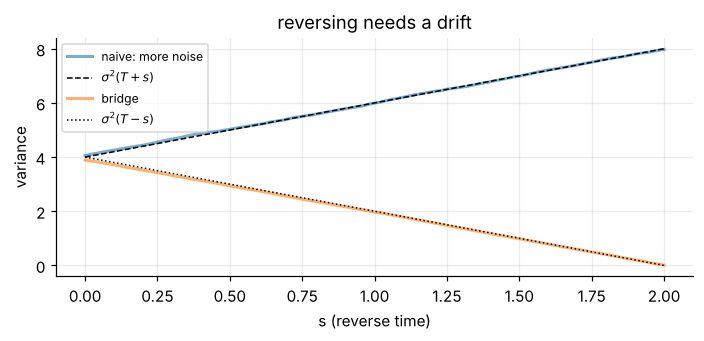

In [12]:
_, Yn = brownian_paths(sigma * np.sqrt(T) * rng.standard_normal(20000), 0.01, T)
print(f"naive reversal: Var at the end = {Yn[-1].var():.2f}   (theory {2 * sigma**2 * T:.0f});  bridge: {Y[-1].var():.4f}")

s_plot = np.arange(0, T + 1e-9, 0.01)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(s_plot, Yn.var(1), lw=2, alpha=0.6, label="naive: more noise")
ax.plot(s_plot, sigma**2 * (T + s_plot), "k--", lw=1, label=r"$\sigma^2(T+s)$")
ax.plot(s_grid, Y.var(1), lw=2, alpha=0.6, label="bridge")
ax.plot(s_grid, sigma**2 * (T - s_grid), "k:", lw=1, label=r"$\sigma^2(T-s)$")
ax.set(xlabel="s (reverse time)", ylabel="variance", title="reversing needs a drift"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5.2 A toy diffusion model: two data points

Now the "data" are two narrow bumps at $\pm a$, with weights $w_\pm$. We need the score of $\rho_t$ to run the process backwards.
It can be computed in four short steps.

**Step 1: a hidden label.** Draw a data point in two stages: toss a coin $K\in\{-,+\}$ with $P(K=\pm)=w_\pm$, which picks the centre
$c_\pm=\pm a$; then $X_0=c_K+s\,\varepsilon_0$. Averaging over the coin gives $\rho_0=w_-\mathcal N(-a,s^2)+w_+\mathcal N(a,s^2)$.

**Step 2: Brownian motion keeps it a mixture.** $X_t=c_K+s\varepsilon_0+\sigma W_t$. Given the coin, this is a sum of independent Gaussians,
so $X_t\mid K\sim\mathcal N(c_K,s_t^2)$ with $s_t^2=s^2+\sigma^2t$: each bump only widens. Hence
$\rho_t=w_-\mathcal N(-a,s_t^2)+w_+\mathcal N(a,s_t^2)$; for large $t$ the two bumps merge into one wide hump.

**Step 3: the score of a mixture.** Since $\partial_y\mathcal N(y;c,s_t^2)=\mathcal N(y;c,s_t^2)\,\frac{c-y}{s_t^2}$,
$$\partial_y\log\rho_t(y)=\frac{\partial_y\rho_t}{\rho_t}=r_-(y)\,\frac{-a-y}{s_t^2}+r_+(y)\,\frac{a-y}{s_t^2},\qquad
r_\pm(y)=\frac{w_\pm\mathcal N(y;\pm a,s_t^2)}{\rho_t(y)} .$$
The score of a mixture is the average of the component scores, weighted by $r_\pm$.

**Step 4: the weights are Bayes' rule.** $r_\pm(y)=P(K=\pm\mid X_t=y)$: the probability that a particle now at $y$ came from bump $\pm$.
Expanding the squares, the common factor $e^{-(y^2+a^2)/2s_t^2}$ cancels and $r_\pm=w_\pm e^{\pm ay/s_t^2}\big/\big(w_+e^{ay/s_t^2}+w_-e^{-ay/s_t^2}\big)$. So
$$\partial_y\log\rho_t(y)=\frac{\hat x_0(y)-y}{s_t^2},\qquad
\hat x_0(y)=\mathbb E[c_K\mid X_t=y]=a\,(r_+-r_-)=a\,\frac{w_+e^{ay/s_t^2}-w_-e^{-ay/s_t^2}}{w_+e^{ay/s_t^2}+w_-e^{-ay/s_t^2}},$$
which is $a\tanh(ay/s_t^2)$ for equal weights. $\hat x_0(y)$ is the **best guess of the data point** a particle at $y$ came from.

**What the reverse drift does.** The drift $\sigma^2\partial_y\log\rho_{T-s}=\frac{\sigma^2}{s_t^2}\big(\hat x_0(y)-y\big)$ is a spring pulling the particle toward
its current guess, with stiffness $\sigma^2/s_t^2$. Example: $a=2$, $\sigma^2=2$, equal weights, a particle at $y=1$:

| | $s_t^2$ | $P(+\mid y)$ | guess $\hat x_0$ | drift |
|---|---|---|---|---|
| high noise, $t=3$ | $6.01$ | $0.66$ | $0.64$ | $-0.12$: weak pull toward the middle |
| low noise, $t=0.1$ | $0.21$ | $\approx1$ | $\approx2$ | $+9.5$: strong push onto the data point |

At high noise the guess is the data average and nothing is decided; at low noise the guess commits and the spring is stiff.
This is exactly how a diffusion model generates data — the network learns $\hat x_0$ (the "denoiser"), or equivalently the score.

We start the reverse process from fresh samples of $\rho_T$: pick a data point and add $\sigma\sqrt T\,\xi$ (one exact step of the
forward process).

In [ ]:
a, s_d = 2.0, 0.1

def score_two(y, t, w_minus=0.5):
    st2 = s_d**2 + sigma**2 * t
    lp, lm = np.log(1 - w_minus) + a * y / st2, np.log(w_minus) - a * y / st2
    x0_hat = a * np.tanh((lp - lm) / 2)                    # = a (w+ e^{..} - w- e^{..}) / (w+ e^{..} + w- e^{..})
    return (x0_hat - y) / st2

def sample_rho_T(n, T, w_minus=0.5):
    """Fresh samples of rho_T: pick a data point, then add the forward noise in one exact step."""
    centre = np.where(rng.random(n) < w_minus, -a, a)
    return centre + s_d * rng.standard_normal(n) + sigma * np.sqrt(T) * rng.standard_normal(n)

T = 3.0
s_grid = np.arange(0, T + 1e-9, 0.002)
y0 = sample_rho_T(20000, T)
Yg = euler_maruyama(lambda s, y: sigma**2 * score_two(y, T - s), y0, s_grid)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), gridspec_kw={"width_ratios": [1.8, 1]})
ax[0].plot(T - s_grid, Yg[:, :25], lw=0.6)
ax[0].axhline(a, color="k", ls=":", lw=1); ax[0].axhline(-a, color="k", ls=":", lw=1)
ax[0].set(xlabel="t  (paths run from right to left)", ylabel="x", title="generation: noise → two data points")
ax[1].hist(Yg[-1], bins=100, range=(-3, 3), density=True)
ax[1].set(xlabel="x", title="generated samples at t = 0")
plt.tight_layout(); plt.show()
print(f"fraction ending near -a: {np.mean(Yg[-1] < 0):.3f}   (data: 0.5)")

Look at the paths: at first ($t$ near 3, high noise) they wander around $0$ — nothing is decided. A particle "chooses" its data
point when the remaining noise variance $s_t^2$ becomes comparable to $a^2$, i.e. around $t\approx a^2/\sigma^2=2$, and after that it is
pulled firmly to it.

**Question (the score knows the proportions).** Make the data unbalanced: $w_-=0.25$, $w_+=0.75$. What fraction of the generated
samples should end near $-a$? Check.

**Solution.** About $25\%$: started from $\rho_T$, the reverse process reproduces the data distribution, including how often each
data point occurs. The weights enter only through the score: in Step 4 the log-odds are
$\log\frac{P(+\mid y)}{P(-\mid y)}=\log\frac{w_+}{w_-}+\frac{2ay}{s_t^2}$, so the prior $\log3$ tilts the guess $\hat x_0$ toward the heavier point at every $y$.
A generative model learns *where* the data are and *how often* they occur.

In the figure below, left: the guess $\hat x_0(y)$ at three noise levels. With 25/75 weights (solid) the curve is shifted left
compared with 50/50 (dashed): a particle has to be further left before the guess says "$-a$". At high noise ($t=3$) the guess is
nearly flat, close to the data average $0.5\cdot2=1$; at low noise ($t=0.1$) it is a sharp switch. Middle: paths coloured by their
final data point. Right: the generated proportions match the data.

In [ ]:
Yu = euler_maruyama(lambda s, y: sigma**2 * score_two(y, T - s, w_minus=0.25), sample_rho_T(20000, T, 0.25), s_grid)
print(f"start from rho_T:  fraction ending near -a = {np.mean(Yu[-1] < 0):.3f}   (data: 0.25)")

def x0_hat(y, t, w_minus):
    st2 = s_d**2 + sigma**2 * t
    return a * np.tanh((np.log((1 - w_minus) / w_minus) + 2 * a * y / st2) / 2)

yv = np.linspace(-6, 6, 400)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5), gridspec_kw={"width_ratios": [1.1, 1.6, 0.9]})
for t_, c in [(3.0, "tab:blue"), (1.0, "tab:green"), (0.1, "tab:red")]:
    ax[0].plot(yv, x0_hat(yv, t_, 0.5), color=c, ls="--", lw=1)
    ax[0].plot(yv, x0_hat(yv, t_, 0.25), color=c, lw=1.8, label=f"t = {t_:g}")
ax[0].axhline(0, color="k", lw=0.5); ax[0].axvline(0, color="k", lw=0.5)
ax[0].set(xlabel="current position y", ylabel=r"guess $\hat x_0(y)$", ylim=(-2.3, 2.3),
          title="best guess: 25/75 (solid) vs 50/50 (dashed)"); ax[0].legend(fontsize=8)
end_left = Yu[-1] < 0
for i in range(40):
    ax[1].plot(T - s_grid, Yu[:, i], lw=0.6, color="tab:purple" if end_left[i] else "tab:olive")
ax[1].axhline(a, color="k", ls=":", lw=1); ax[1].axhline(-a, color="k", ls=":", lw=1)
ax[1].set(xlabel="t  (paths run from right to left)", ylabel="x", title="paths coloured by where they end")
ax[2].bar(["data", "generated"], [0.25, np.mean(end_left)], color="tab:purple", label="near -a")
ax[2].bar(["data", "generated"], [0.75, 1 - np.mean(end_left)], bottom=[0.25, np.mean(end_left)], color="tab:olive", label="near +a")
ax[2].set(ylabel="fraction", title="proportions are reproduced"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Question (the starting distribution).** Real diffusion models do not know $\rho_T$; they start the reverse process from "pure
noise". Start from $\mathcal N(0,\sigma^2T)$ instead of $\rho_T$, with the unbalanced data of Question 8. Before running: what is the mean
of $\rho_T$? (Hint: Section 2 — how does Brownian motion change the mean?) What do you expect for the $25\%$?

**Solution.** Brownian motion does not change the mean, so $\mathbb E X_T=\mathbb E X_0=(w_+-w_-)a=0.5\cdot2=1$, not $0$. Its variance is
$\mathrm{Var}\,c_K+s^2+\sigma^2T=a^2\big(1-(w_+-w_-)^2\big)+s^2+\sigma^2T=3+0.01+6\approx9$, not $6$. "Pure noise" is shifted to the left and too
narrow, so too many particles start on the left side and are sent to $-a$: about $32\%$ instead of $25\%$. The reverse dynamics
cannot repair a wrong start.

This is why practical diffusion models either make the final noise much larger than the data ($\sigma^2T\gg a^2$; variance-exploding
models), or add a drift that makes the forward process forget the data, so that $\rho_T\approx\mathcal N(0,1)$ really holds (DDPM).

In the figure below, left: the true $\rho_T$ and the "pure noise" start, which is too far left and too narrow. Middle: the generated
samples; the left bump gets too much mass. Right: the same experiment with longer noising times. The mean offset $1$ stays, but it
becomes small compared with the spread $\sigma\sqrt T$, so the error shrinks toward $0.25$ (slowly, roughly like $1/\sqrt T$).

In [ ]:
Yw = euler_maruyama(lambda s, y: sigma**2 * score_two(y, T - s, w_minus=0.25), sigma * np.sqrt(T) * rng.standard_normal(20000), s_grid)
yT_true = sample_rho_T(200000, T, 0.25)
print(f"rho_T: mean {yT_true.mean():.2f}, variance {yT_true.var():.2f};   pure noise N(0, sigma^2 T): mean 0, variance {sigma**2 * T:.0f}")
print(f"start from N(0, sigma^2 T): fraction ending near -a = {np.mean(Yw[-1] < 0):.3f}   (data: 0.25)")

def reverse_from_noise(T_, n=5000, w_minus=0.25):
    """Reverse SDE from pure noise N(0, sigma^2 T_); time grid refined geometrically near t = 0."""
    t_nodes = np.concatenate([T_ * (1e-4 / T_) ** np.linspace(0, 1, 3000), [0.0]])
    y = euler_maruyama(lambda s_, y_: sigma**2 * score_two(y_, T_ - s_, w_minus), sigma * np.sqrt(T_) * rng.standard_normal(n),
                       T_ - t_nodes)
    return np.mean(y[-1] < 0)

T_list = [3, 10, 30, 100, 300]
frac_noise = [reverse_from_noise(T_) for T_ in T_list]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
yv = np.linspace(-10, 10, 500)
rho_T = 0.25 * norm.pdf(yv, -a, np.sqrt(s_d**2 + sigma**2 * T)) + 0.75 * norm.pdf(yv, a, np.sqrt(s_d**2 + sigma**2 * T))
ax[0].plot(yv, rho_T, lw=2, label=r"true $\rho_T$ (mean 1, var 9)")
ax[0].plot(yv, norm.pdf(yv, 0, sigma * np.sqrt(T)), "k--", lw=1.2, label=r"pure noise $\mathcal{N}(0,\sigma^2T)$")
ax[0].axvline(0, color="k", lw=0.5); ax[0].set(xlabel="y", title="the two starting distributions (T = 3)"); ax[0].legend(fontsize=8)
ax[1].hist(Yu[-1], bins=100, range=(-3, 3), density=True, histtype="step", lw=1.5, label=r"start from $\rho_T$")
ax[1].hist(Yw[-1], bins=100, range=(-3, 3), density=True, histtype="step", lw=1.5, color="tab:red", label="start from pure noise")
ax[1].set(xlabel="x", title="generated samples: the left bump is too heavy"); ax[1].legend(fontsize=8)
ax[2].semilogx(T_list, frac_noise, "o-", color="tab:red", label="start from pure noise")
ax[2].axhline(0.25, color="k", ls="--", lw=1, label="data: 0.25")
ax[2].set(xlabel=r"final time T (noise variance $\sigma^2T$)", ylabel="fraction near -a",
          title=r"the fix: make $\sigma^2T\gg a^2$"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
for T_, fr in zip(T_list, frac_noise):
    print(f"T = {T_:4d} (sigma^2 T = {sigma**2 * T_:5.0f}):  fraction near -a = {fr:.3f}")